# PH 217 Project: Milankovitch Cycles and Ice Ages

**What this notebook does.** Earth's spin axis and orbit change slowly over tens of thousands of years, which changes how sunlight is spread over latitudes and seasons. We derive the periods of those changes from Newtonian mechanics and compare them with the ice-age record.

| Part | Question | Status |
|---|---|---|
| A | How fast does the spin axis precess under the torque of Sun and Moon? | derived, computed, verified against unaveraged integration |
| B | What are the slow frequencies of Earth's orbital eccentricity? | first-order (Laplace-Lagrange) done, compared with Laskar |
| C | Which planets are needed to get the ~100 and ~400 kyr terms? | tested |
| D | Climatic precession (19 to 23 kyr) | computed |
| E | Obliquity (41 kyr), insolation at 65°N, comparison with the LR04 δ¹⁸O record, the 100 kyr problem | done |

Part B.3 checks the first-order theory against a direct N-body integration, and Part A.4 looks at the small gap between the computed and observed precession rate.

*AI statement for the report: AI was used for derivation outlines, code and checking. Every number below is produced by code in this notebook and each step must be explainable by the group.*

In [1]:
# Setup: installs any missing package into THIS kernel's Python, so the notebook runs on a fresh environment.
import importlib, subprocess, sys
for pkg in ("numpy", "scipy", "matplotlib"):
    try:
        importlib.import_module(pkg)
    except ImportError:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pkg])

In [2]:
import numpy as np, matplotlib.pyplot as plt
from scipy.integrate import quad, solve_ivp
from functools import lru_cache
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .3})

ASEC_REV = 360*3600.0          # arcsec in one full turn
def kyr(rate_arcsec_per_yr):   # period in kyr for an angular rate in arcsec/yr
    return ASEC_REV/abs(rate_arcsec_per_yr)/1e3

## Part A: Precession of the spin axis

### A.1 Setup
Earth is an oblate spheroid with moments of inertia $C$ (about the spin axis) and $A$ (about an equatorial axis), with $C>A$. A distant mass $M$ at position $\mathbf r=r\hat{\mathbf r}$ gives a gravitational torque on this equatorial bulge (from the quadrupole term of the potential, $\hat{\mathbf s}$ is the spin axis direction):

$$\mathbf N = \frac{3GM}{r^3}\,(C-A)\,(\hat{\mathbf r}\cdot\hat{\mathbf s})\,(\hat{\mathbf r}\times\hat{\mathbf s}).$$

The torque is perpendicular to $\hat{\mathbf s}$, so it changes the **direction** of the spin angular momentum $\mathbf L = C\omega\,\hat{\mathbf s}$ and not its size:

$$\dot{\hat{\mathbf s}} = \frac{\mathbf N}{C\omega} = \frac{3GM}{\omega r^3}\,H\,(\hat{\mathbf r}\cdot\hat{\mathbf s})(\hat{\mathbf r}\times\hat{\mathbf s}),\qquad H=\frac{C-A}{C}.$$

### A.2 Orbit average
Take the ecliptic as the $xy$-plane and the Sun orbiting in it. Let the spin axis be $\hat{\mathbf s}=(\sin\varepsilon,0,\cos\varepsilon)$ at an instant ($\varepsilon$ is the obliquity). For a circular orbit $\hat{\mathbf r}=(\cos\theta,\sin\theta,0)$:

$$\hat{\mathbf r}\cdot\hat{\mathbf s}=\sin\varepsilon\cos\theta,\qquad \hat{\mathbf r}\times\hat{\mathbf s}=(\sin\theta\cos\varepsilon,\,-\cos\theta\cos\varepsilon,\,-\sin\theta\sin\varepsilon).$$

Averaging over $\theta$ ($\langle\cos^2\theta\rangle=\tfrac12$, $\langle\sin\theta\cos\theta\rangle=0$) leaves only the $y$-component:

$$\langle\dot s_y\rangle=-\frac{3GMH}{2\omega a^3}\sin\varepsilon\cos\varepsilon .$$

A motion of $\hat{\mathbf s}$ along $-y$ at fixed $\varepsilon$ is a **rotation about the ecliptic normal** with angular rate $\dot\psi=\langle\dot s_y\rangle/\sin\varepsilon$. To leading order in the small yearly motion of $\hat{\mathbf s}$, and with the orbit treated as an ellipse in a fixed plane, this gives

$$\boxed{\dot\psi=-\frac{3}{2}\,H\,\frac{GM}{a^3(1-e^2)^{3/2}}\,\frac{\cos\varepsilon}{\omega}}$$

(the minus sign means retrograde, like the observed precession of the equinoxes; the factor $(1-e^2)^{-3/2}$ is the eccentric-orbit average). The Moon gives the same form with $M\to M_\text{moon}$, $a\to a_\text{moon}$.

In [3]:
G = 6.67430e-11; Msun = 1.98841e30; Mmoon = 7.3459e22; AU = 1.495978707e11
a_moon = 3.844e8; e_earth = 0.0167; e_moon = 0.0549
eps = np.radians(23.439)                    # obliquity, J2000
omega = 2*np.pi/86164.0905                  # spin rate (sidereal day)
H = 0.0032737                               # dynamical ellipticity (C-A)/C
sec_per_yr = 365.25*86400

def prec_rate(M, a, e):                     # rad/s, negative = retrograde
    return -1.5*H*(G*M/(a**3*(1-e**2)**1.5))*np.cos(eps)/omega
to_as = lambda r: np.degrees(r*sec_per_yr)*3600

r_sun, r_moon = prec_rate(Msun, AU, e_earth), prec_rate(Mmoon, a_moon, e_moon)
p_total = to_as(r_sun + r_moon)
print(f"Sun   {to_as(r_sun):8.3f} arcsec/yr")
print(f"Moon  {to_as(r_moon):8.3f} arcsec/yr   (Moon/Sun = {r_moon/r_sun:.2f})")
print(f"Total {p_total:8.3f} arcsec/yr  ->  period {kyr(p_total):.1f} kyr")
print("IAU 2006 value of the equatorial (lunisolar) precession rate: 50.385 arcsec/yr (Part A.4).")

Sun    -15.949 arcsec/yr
Moon   -34.872 arcsec/yr   (Moon/Sun = 2.19)
Total  -50.820 arcsec/yr  ->  period 25.5 kyr
IAU 2006 value of the equatorial (lunisolar) precession rate: 50.385 arcsec/yr (Part A.4).


### A.3 Check: does orbit-averaging really work?
The averaged formula assumes the spin axis hardly moves during one year. We test that by integrating $\dot{\hat{\mathbf s}}$ with the **unaveraged** torque along a true Kepler ellipse (Sun only), for 3000 years, and fitting the precession rate. (We use the gyroscopic limit $L=C\omega$ fixed, which is a leading-order approximation for a rapidly spinning body; resolving every rotation would need ~$10^9$ steps for no extra insight.)

e=0.0000: unaveraged  -15.942  averaged  -15.942 arcsec/yr  (diff -0.0007%)


e=0.0167: unaveraged  -15.949  averaged  -15.949 arcsec/yr  (diff -0.0007%)


e=0.2000: unaveraged  -16.949  averaged  -16.949 arcsec/yr  (diff -0.0008%)


obliquity wobble over one year, peak to peak: 3.09e-04 deg


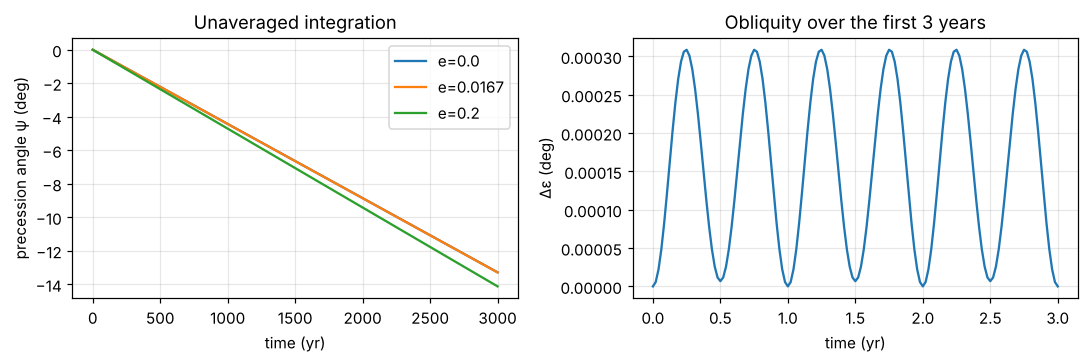

In [4]:
GM = 4*np.pi**2                    # AU^3/yr^2
omega_y = 2*np.pi*366.2564         # rad/yr
eps0 = np.radians(23.439)

def unaveraged(e, T=3000.0):
    n = 2*np.pi
    def rhat_r(t):
        M = n*t; E = M
        for _ in range(8): E -= (E - e*np.sin(E) - M)/(1 - e*np.cos(E))   # Kepler's equation
        r = 1 - e*np.cos(E)
        return np.array([np.cos(E)-e, np.sqrt(1-e*e)*np.sin(E), 0.0])/r, r
    def f(t, s):
        rh, r = rhat_r(t)
        return 3*GM*H/(omega_y*r**3)*(rh@s)*np.cross(rh, s)
    s0 = np.array([np.sin(eps0), 0, np.cos(eps0)])
    sol = solve_ivp(f, (0, T), s0, method="DOP853", rtol=1e-11, atol=1e-13, t_eval=np.arange(0.0, T + 1e-9, 1/48.))
    psi = np.unwrap(np.arctan2(sol.y[1], sol.y[0]))
    obl = np.degrees(np.arccos(sol.y[2]))
    rate = np.degrees(np.polyfit(sol.t, psi, 1)[0])*3600
    avg = np.degrees(-1.5*H*GM/(1-e*e)**1.5/omega_y*np.cos(eps0))*3600
    return sol.t, psi, obl, rate, avg

fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
for e in (0.0, 0.0167, 0.2):
    t, psi, obl, rate, avg = unaveraged(e)
    print(f"e={e:6.4f}: unaveraged {rate:8.3f}  averaged {avg:8.3f} arcsec/yr  (diff {100*(rate-avg)/avg:+.4f}%)")
    ax[0].plot(t, np.degrees(psi), label=f"e={e}")
ax[0].set(xlabel="time (yr)", ylabel="precession angle ψ (deg)", title="Unaveraged integration"); ax[0].legend()
t, psi, obl, *_ = unaveraged(0.0167)
n3 = 3*48 + 1                                   # first 3 years, sampled every 1/48 yr
ax[1].plot(t[:n3], obl[:n3]-obl[0]); ax[1].set(xlabel="time (yr)", ylabel="Δε (deg)", title="Obliquity over the first 3 years")
print(f"obliquity wobble over one year, peak to peak: {np.ptp(obl[:49]):.2e} deg")
plt.tight_layout(); plt.show()

**Result.** The unaveraged and averaged precession rates agree to ~$10^{-3}$ %, and the obliquity wobbles by only ~$3\times10^{-4}$ deg peak to peak within a year, with no drift. Averaging is justified for the precession, so the gap between the A.2 total (50.82″/yr) and the IAU value (50.385″/yr) is not caused by it. Part A.4 takes up the gap.

### A.4 The gap in the precession rate
The Sun-plus-Moon total from A.2 is 1 % above the IAU 2006 rate of the equator (50.385″/yr), and the difference has three possible sources: the tilt of the lunar orbit, the choice of $a$, $e$ and $\varepsilon$ constants, and the planets.

**Lunar orbit tilt.** The Moon's orbit is inclined by $i\approx5.145^\circ$ to the ecliptic, and its node regresses with a period of 18.6 yr. Averaged over the node, the unit normal $\hat{\mathbf k}'$ of the lunar orbit has $\langle k'_xk'_x\rangle=\langle k'_yk'_y\rangle=\tfrac12\sin^2 i$ and $\langle k'_zk'_z\rangle=\cos^2 i$. The orbit-averaged lunar torque on the bulge has the form of A.2 with $\hat z\hat z$ replaced by this tensor, and the precession rate is multiplied by
$$\cos^2 i-\tfrac12\sin^2 i=1-\tfrac32\sin^2 i=0.9879 .$$
The Sun's own ecliptic is the $i=0$ case. This lowers the Moon's part by 1.2 %, i.e. by about 0.42″/yr.

In [5]:
f_tilt = 1 - 1.5*np.sin(np.radians(5.145))**2
p_sun, p_moon = to_as(r_sun), to_as(r_moon)
print(f"A.2 total (mean elements)        {p_sun + p_moon:8.3f} arcsec/yr")
print(f"tilt factor 1 - 1.5 sin^2 i      {f_tilt:8.4f}")
print(f"with lunar tilt                  {p_sun + f_tilt*p_moon:8.3f} arcsec/yr   (IAU 2006: -50.385)")

A.2 total (mean elements)         -50.820 arcsec/yr
tilt factor 1 - 1.5 sin^2 i        0.9879
with lunar tilt                   -50.399 arcsec/yr   (IAU 2006: -50.385)


**Using the true positions.** The mean-element formula uses $a^{-3}(1-e^2)^{-3/2}$ for nominal circular-plus-eccentricity orbits. The torque actually goes as $\langle r^{-3}\rangle$ over the real motion. We average the torque over real ephemerides (ERFA `epv00` for the Sun, `moon98` for the Moon [18]), with the spin axis held at the J2000 pole, over 56 yr for the Sun and 3 nodal cycles for the Moon. The window length matters: a Sun window that is not a whole number of years leaves a seasonal bias.

In [6]:
try:
    import erfa
except ImportError:
    import subprocess, sys; subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "pyerfa"]); import erfa

AU_km = 149597870.7; GM_sun_d = 0.01720209895**2                       # AU^3/day^2 (Gauss)
GM_moon_d = 4902.8001*86400.0**2/AU_km**3                              # AU^3/day^2
omega_d = 2*np.pi/0.99726957                                           # rad/day (sidereal)
eps_J = np.radians(23.4392911); s_pole = np.array([0, 0, 1.0])         # spin axis = J2000 equatorial pole
ecl_n = np.array([0, -np.sin(eps_J), np.cos(eps_J)]); ax_prec = np.cross(ecl_n, s_pole)   # axis about which s precesses

def ephemeris_rate(pos_fn, GM, span_days):
    days = np.arange(-span_days/2, span_days/2, 0.2); jd1 = np.full_like(days, 2451545.0)
    r = pos_fn(jd1, days); rn = np.linalg.norm(r, axis=1); rh = r/rn[:, None]
    torque = ((rh @ s_pole)[:, None]*np.cross(rh, s_pole)/(rn**3)[:, None]).mean(axis=0)
    sdot = 3*H*GM/omega_d*torque                                      # rad/day
    return np.degrees((sdot @ ax_prec)/(ax_prec @ ax_prec))*3600*365.25
NODAL_D = 6798.38                                                      # days, 18.6 yr
r_sun_eph  = ephemeris_rate(lambda j1, d: -erfa.epv00(j1, d)[0]['p'], GM_sun_d, 56*365.25)
r_moon_eph = ephemeris_rate(lambda j1, d: erfa.moon98(j1, d)['p'], GM_moon_d, 3*NODAL_D)
print(f"Sun {r_sun_eph:.3f}   Moon {r_moon_eph:.3f}   total {r_sun_eph + r_moon_eph:.3f} arcsec/yr    IAU 2006: -50.385")
print(f"difference from IAU: {r_sun_eph + r_moon_eph + 50.385:+.3f} arcsec/yr ({100*(r_sun_eph + r_moon_eph + 50.385)/-50.385:+.2f} %)")

Sun -15.948   Moon -34.456   total -50.404 arcsec/yr    IAU 2006: -50.385
difference from IAU: -0.019 arcsec/yr (+0.04 %)


Two different checks are made here. The mean-element formula with the lunar tilt factor gives 50.399″/yr, 0.03 % above the IAU value, and the real-ephemeris average gives 50.404″/yr, 0.04 % above it. The lunar tilt accounts for most of the 0.9 % discrepancy of the A.2 total (50.82″/yr). $H$ is taken from observation of the precession itself, so the agreement tests the torque formula and the tilt factor, and not $H$.

**Planetary precession and which rate to use later.** The planets rotate the ecliptic itself. This subtracts about $\chi_A\cos\varepsilon\approx0.097''$/yr from the equator's precession, giving the general precession in longitude $p_A=50.288''$/yr (IAU 2006: 5028.796″/cy) against $\bar\psi=50.385''$/yr (5038.481″/cy) [19]. Part D uses $p_A$, since it is the rate at which the equinox moves along the moving ecliptic, and Part E.1 uses $\bar\psi$ for the torque on the bulge.

## Part B: Secular eccentricity (Laplace-Lagrange)

### B.1 Idea
Planets tug on each other's orbits [1]. Averaging the disturbing function over the fast mean longitudes leaves the slow evolution of $h_j=e_j\sin\varpi_j$, $k_j=e_j\cos\varpi_j$ ($\varpi$ = longitude of perihelion). To first order in the masses and eccentricities it is **linear**:

$$\frac{d\mathbf z}{dt}=+i\,\mathsf A\,\mathbf z,\qquad z_j=k_j+ih_j=e_je^{i\varpi_j},$$

$$A_{jj}=\frac{n_j}{4}\sum_{k\ne j}\frac{m_k}{M_\odot+m_j}\,\alpha_{jk}\bar\alpha_{jk}\,b^{(1)}_{3/2}(\alpha_{jk}),\qquad A_{jk}=-\frac{n_j}{4}\frac{m_k}{M_\odot+m_j}\,\alpha_{jk}\bar\alpha_{jk}\,b^{(2)}_{3/2}(\alpha_{jk}),$$

with $\alpha_{jk}=\min(a_j,a_k)/\max(a_j,a_k)$, $\bar\alpha_{jk}=\alpha_{jk}$ if planet $j$ is the inner one and $1$ otherwise, and the Laplace coefficients

$$b^{(j)}_{s}(\alpha)=\frac1\pi\int_0^{2\pi}\frac{\cos j\psi}{(1-2\alpha\cos\psi+\alpha^2)^{s}}\,d\psi .$$

Eigenvalues $g_i$ of $\mathsf A$ are the secular frequencies (positive: perihelia advance). Earth's $z_\oplus(t)$ is a sum of modes with frequencies $g_i$, so $e^2=|z_\oplus|^2$ contains only the **differences** $g_i-g_j$, exactly. $e=|z_\oplus|$ is the square root of that and so has the same difference frequencies plus their combinations.

In [7]:
names = ["Mercury","Venus","Earth","Mars","Jupiter","Saturn","Uranus","Neptune"]
a  = np.array([0.38710, 0.72333, 1.00000, 1.52368, 5.20336, 9.53707, 19.1913, 30.0690])      # AU
m  = np.array([1.6601e-7, 2.4478e-6, 3.0404e-6, 3.2271e-7, 9.5479e-4, 2.8589e-4, 4.3662e-5, 5.1514e-5])  # Msun (Earth = Earth+Moon)
e0 = np.array([0.20563, 0.00677, 0.01671, 0.09341, 0.04839, 0.05415, 0.04717, 0.00859])      # J2000
pi0 = np.radians([77.46, 131.53, 102.94, 336.04, 14.75, 92.43, 170.96, 44.97])

@lru_cache(maxsize=None)
def laplace_b(s, j, al):
    return quad(lambda p: np.cos(j*p)/(1-2*al*np.cos(p)+al*al)**s, 0, 2*np.pi, limit=200)[0]/np.pi

def secular(idx):
    '''Laplace-Lagrange for the planets with indices idx. Returns g (arcsec/yr, sorted), eigenvectors V (columns), and mode coefficients c with z(0) = V c.'''
    aa, mm = a[idx], m[idx]; n = ASEC_REV/aa**1.5; N = len(idx)
    A = np.zeros((N, N))
    for j in range(N):
        for k in range(N):
            if j == k: continue
            al, alb = (aa[j]/aa[k],)*2 if aa[j] < aa[k] else (aa[k]/aa[j], 1.0)
            c = 0.25*n[j]*mm[k]/(1+mm[j])*al*alb
            A[j, j] += c*laplace_b(1.5, 1, al); A[j, k] = -c*laplace_b(1.5, 2, al)
    g, V = np.linalg.eig(A); o = np.argsort(g.real); g, V = g.real[o], V.real[:, o]
    z0 = e0[idx]*np.cos(pi0[idx]) + 1j*e0[idx]*np.sin(pi0[idx])
    return g, V, np.linalg.solve(V, z0)

def earth_e(idx, t):
    g, V, coef = secular(idx); ie = list(idx).index(2)
    z = sum(V[ie, i]*coef[i]*np.exp(+1j*np.radians(g[i]/3600)*t) for i in range(len(idx)))
    return np.abs(z)

g_all, V_all, coef_all = secular(np.arange(8))
# physical labels of the sorted modes (verified below against the textbook table)
labels = ["g8","g7","g5","g1","g2","g3","g4","g6"]
textbook_LL = dict(g1=5.462, g2=7.346, g3=17.33, g4=18.00, g5=3.724, g6=22.44, g7=2.708, g8=0.6345)   # Brouwer & van Woerkom / Murray & Dermott
laskar_2011 = dict(g1=5.59,  g2=7.453, g3=17.368, g4=17.916, g5=4.2575, g6=28.245, g7=3.0879, g8=0.6730)  # full N-body fit (La2010)
for lab, gi in zip(labels, g_all):
    assert abs(gi - textbook_LL[lab]) < 0.1, (lab, gi)    # reproduces the textbook first-order table
print("mode   ours   textbook-LL   Laskar   error vs Laskar")
for lab in sorted(labels):
    gi = g_all[labels.index(lab)]
    print(f" {lab}   {gi:6.3f}   {textbook_LL[lab]:7.3f}     {laskar_2011[lab]:7.3f}    {100*(gi-laskar_2011[lab])/laskar_2011[lab]:+6.1f}%")

mode   ours   textbook-LL   Laskar   error vs Laskar
 g1    5.461     5.462       5.590      -2.3%
 g2    7.345     7.346       7.453      -1.4%
 g3   17.329    17.330      17.368      -0.2%
 g4   18.002    18.000      17.916      +0.5%
 g5    3.730     3.724       4.258     -12.4%
 g6   22.510    22.440      28.245     -20.3%
 g7    2.707     2.708       3.088     -12.3%
 g8    0.635     0.634       0.673      -5.7%


Our eigenfrequencies reproduce the first-order table of Fitzpatrick's notes [2], which follows the classical secular theory of [3]. They differ from the accurate values [4] for $g_5$ ($-12\%$) and $g_6$ ($-20\%$): the Jupiter-Saturn pair sits near the 5:2 resonance (the "Great Inequality"), where first-order theory is poor [5]. Part B.3 measures the same error with an N-body integration.

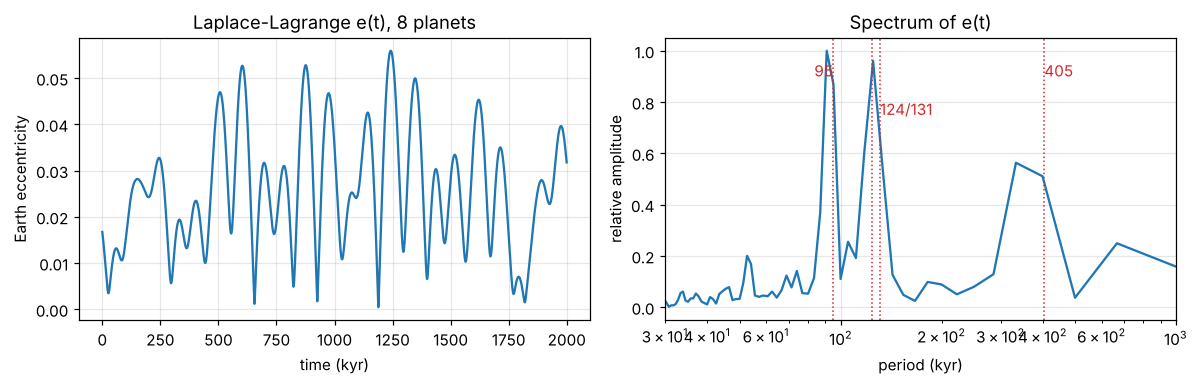

e range: 0.0004 to 0.0559 | spectral peaks (kyr): [91, 125, 333, 105, 667]


In [8]:
t = np.arange(0, 2.0e6, 500.0)                       # 2 Myr, 500 yr step
e_t = earth_e(np.arange(8), t)
sig = e_t - e_t.mean(); F = np.abs(np.fft.rfft(sig*np.hanning(len(sig)))); fr = np.fft.rfftfreq(len(sig), 500.0)

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].plot(t/1e3, e_t); ax[0].set(xlabel="time (kyr)", ylabel="Earth eccentricity", title="Laplace-Lagrange e(t), 8 planets")
per = 1/fr[1:]/1e3
ax[1].plot(per, F[1:]/F.max()); ax[1].set(xscale="log", xlim=(30, 1000), xlabel="period (kyr)", ylabel="relative amplitude", title="Spectrum of e(t)")
for p in (95, 124, 131, 405): ax[1].axvline(p, color="C3", ls=":", lw=1)
ax[1].text(405, .9, "405", color="C3"); ax[1].text(95, .9, "95", color="C3", ha="right"); ax[1].text(131, .75, "124/131", color="C3")
plt.tight_layout(); plt.show()
pk = sorted([i for i in range(2, len(F)-1) if F[i] > F[i-1] and F[i] > F[i+1] and F[i] > .1*F.max()], key=lambda i: -F[i])[:5]
print("e range: %.4f to %.4f" % (e_t.min(), e_t.max()), "| spectral peaks (kyr):", [round(1/fr[i]/1e3) for i in pk])

### B.2 Beat periods: first-order vs accurate frequencies
Earth's eccentricity amplitudes are dominated by $g_2,g_3,g_4,g_5$. The periods of $e$ come from their differences.

In [9]:
pairs = [("g2","g5","405 kyr term"), ("g4","g5","~95 kyr"), ("g3","g5","~99 kyr"), ("g4","g2","~124 kyr"), ("g3","g2","~131 kyr")]
print("beat    ours (kyr)   with Laskar g (kyr)   note")
for x, y, note in pairs:
    ours = kyr(g_all[labels.index(x)] - g_all[labels.index(y)])
    lask = kyr(laskar_2011[x] - laskar_2011[y])
    print(f"{x}-{y}   {ours:8.1f}      {lask:8.1f}            {note}")

beat    ours (kyr)   with Laskar g (kyr)   note
g2-g5      358.5         405.6            405 kyr term
g4-g5       90.8          94.9            ~95 kyr
g3-g5       95.3          98.9            ~99 kyr
g4-g2      121.6         123.9            ~124 kyr
g3-g2      129.8         130.7            ~131 kyr


### B.3 Check against a direct N-body integration
To estimate the error of the first-order theory, we integrate the Sun and eight planets directly with Newtonian gravity (REBOUND [16], WHFast [17], 3-day step), starting from the J2000 positions and velocities given by the ERFA `plan94` planetary theory [18], 2.6 Myr back in time. Every 1 kyr we store the eccentricity vector $z=e\,e^{i\varpi}$ and the node vector $\zeta=\sin I\,e^{i\Omega}$ of each planet, averaged over 10 samples spread over 180 yr to remove the short-period terms. The frequencies are then measured from the stored $z(t)$ by a windowed Fourier transform with a frequency refinement step (the idea of Laskar's NAFF method). Each stored sample is the mean over a 180-yr window and is assigned to the centre of that window, 90 yr before the label time. The integration takes about 7 min, so the result is cached in `nbody_erfa_2p6Myr.npz`; the cell recomputes it if the file is missing (it then installs `rebound` and `pyerfa` if they are absent).

The two calculations are not initialised identically. Laplace–Lagrange uses the mean elements, masses and semimajor axes listed in B.1, and the N-body run uses osculating states from `plan94` (for example Saturn starts at $a=9.558$ AU and $e=0.0555$, against 9.537 AU and 0.0542 in B.1) and slightly different masses. The comparison below is therefore between two approximately initialised models: the differences combine the first-order truncation with the different starting orbits, and the phase drift of $e(t)$ cannot be attributed to $g_5$ and $g_6$ alone.

This integration has no general relativity and no separate Moon (Earth's mass includes the Moon's), unlike the La2010 solution [4], so the inner-planet frequencies can differ from the La2010 values by the relativistic perihelion advance (0.43″/yr for Mercury).

In [10]:
import os
from scipy.optimize import minimize_scalar

def run_nbody(T_yr=2.6e6, dt_days=3.0, out="nbody_erfa_2p6Myr.npz"):
    # Newtonian N-body, initial osculating states from ERFA plan94 at J2000. Needs: pip install rebound pyerfa (about 7 min).
    try:
        import rebound, erfa
    except ImportError:
        import subprocess, sys; subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "rebound", "pyerfa"]); import rebound, erfa
    YR = 365.25; eps_ = np.radians(23.4392911)
    mass = [1/6023600., 1/408523.71, 1/328900.56, 1/3098708., 1/1047.3486, 1/3497.898, 1/22902.98, 1/19412.24]   # planet/Sun mass (Earth incl. Moon)
    Rm = np.array([[1, 0, 0], [0, np.cos(eps_), np.sin(eps_)], [0, -np.sin(eps_), np.cos(eps_)]])             # equatorial -> ecliptic
    sim = rebound.Simulation(); sim.G = 0.01720209895**2; sim.add(m=1.0)
    for i, mi in enumerate(mass):
        pv = erfa.plan94(2451545.0, 0.0, i+1); p = Rm@np.array(pv['p']).reshape(3); v = Rm@np.array(pv['v']).reshape(3)
        sim.add(m=mi, x=p[0], y=p[1], z=p[2], vx=v[0], vy=v[1], vz=v[2])
    sim.move_to_com(); sim.integrator = "whfast"; sim.integrator.safe_mode = 0; sim.integrator.corrector = 11; sim.dt = -abs(dt_days)
    nk = int(T_yr/1e3) + 1; Zs = np.zeros((nk, 8), complex); Zt = np.zeros((nk, 8), complex)
    for k in range(nk):
        for j in range(10):                                           # 10 samples over 180 yr, then average
            sim.integrate(-(k*1000.0*YR + j*20.0*YR))
            for i, o in enumerate(sim.orbits(primary=sim.particles[0])):
                Zs[k, i] += o.e*np.exp(1j*o.pomega)/10; Zt[k, i] += np.sin(o.inc)*np.exp(1j*o.Omega)/10
    np.savez(out, t_kyr=-(np.arange(nk) + 0.09), Z=Zs, ZETA=Zt)     # label = centre of the 180-yr averaging window

def naff(z, t, nf=8, pad=8):
    # frequencies (arcsec/yr) and complex amplitudes of the nf strongest terms of z(t), found one at a time
    t = t - t.mean(); N = len(t); dt = t[1]-t[0]; T = t[-1]-t[0]
    w = 0.5*(1 + np.cos(2*np.pi*t/(T + dt)))                          # Hann window
    resid = z.astype(complex).copy(); om = []
    for _ in range(nf):
        zz = resid*w; F = np.abs(np.fft.fft(zz, n=pad*N)); grid = np.fft.fftfreq(pad*N, d=dt)*2*np.pi
        w0 = grid[np.argmax(F)]; dw = 3*2*np.pi/(T*pad)
        om.append(minimize_scalar(lambda x: -abs(np.sum(zz*np.exp(-1j*x*t))), bounds=(w0-dw, w0+dw), method="bounded", options={"xatol": 1e-14}).x)
        Bm = np.exp(1j*np.outer(t, om)); coef = np.linalg.lstsq(Bm, z, rcond=None)[0]; resid = z - Bm@coef
    return np.degrees(np.array(om))*3600, coef

if not os.path.exists("nbody_erfa_2p6Myr.npz"):
    run_nbody()
nb = np.load("nbody_erfa_2p6Myr.npz"); t_nb = (nb["t_kyr"]*1e3)[::-1]; Z_nb = nb["Z"][::-1]          # ascending time (yr)

# Reference-guided mode identification: each mode is read from the planet where it is strong, taking the term closest to the La2010 value
# (within 8 %) among those with amplitude > 10 % of that planet's largest. This is not a blind recovery of the frequencies.
planet_of = dict(g5=4, g6=5, g7=6, g8=7, g1=2, g2=2, g3=2, g4=2)
fq = {}; used = set(); spectra = {}
for lab in ("g5", "g6", "g7", "g8", "g1", "g2", "g3", "g4"):
    j = planet_of[lab]
    if j not in spectra: spectra[j] = naff(Z_nb[:, j], t_nb)
    f, c = spectra[j]; amp = np.abs(c)
    ok = [i for i in range(len(f)) if amp[i] > 0.1*amp.max() and abs(f[i]-laskar_2011[lab]) < 0.08*laskar_2011[lab] and (j, i) not in used]
    i = min(ok, key=lambda i: abs(f[i]-laskar_2011[lab])); used.add((j, i)); fq[lab] = f[i]

i_of = {lab: labels.index(lab) for lab in labels}
print("mode  first-order LL   N-body   La2010   LL error vs N-body   N-body vs La2010")
for lab in sorted(labels):
    gl = g_all[i_of[lab]]
    print(f" {lab}     {gl:7.3f}      {fq[lab]:7.3f}  {laskar_2011[lab]:7.3f}      {100*(gl-fq[lab])/fq[lab]:+6.1f}%            {100*(fq[lab]-laskar_2011[lab])/laskar_2011[lab]:+6.1f}%")

mode  first-order LL   N-body   La2010   LL error vs N-body   N-body vs La2010
 g1       5.461        5.231    5.590        +4.4%              -6.4%
 g2       7.345        7.341    7.453        +0.1%              -1.5%
 g3      17.329       17.693   17.368        -2.1%              +1.9%
 g4      18.002       18.038   17.916        -0.2%              +0.7%
 g5       3.730        4.249    4.258       -12.2%              -0.2%
 g6      22.510       26.920   28.245       -16.4%              -4.7%
 g7       2.707        2.987    3.088        -9.4%              -3.3%
 g8       0.635        0.675    0.673        -6.0%              +0.3%


window (kyr)   rms(e_nbody - e_LL)   correlation   best lag (kyr)   correlation at best lag
   0-200          0.0036               0.943           +6             0.970
   0-500          0.0092               0.666          +15             0.801
   0-1000         0.0156               0.255          +21             0.583
   0-2600         0.0178               0.041          +25             0.249


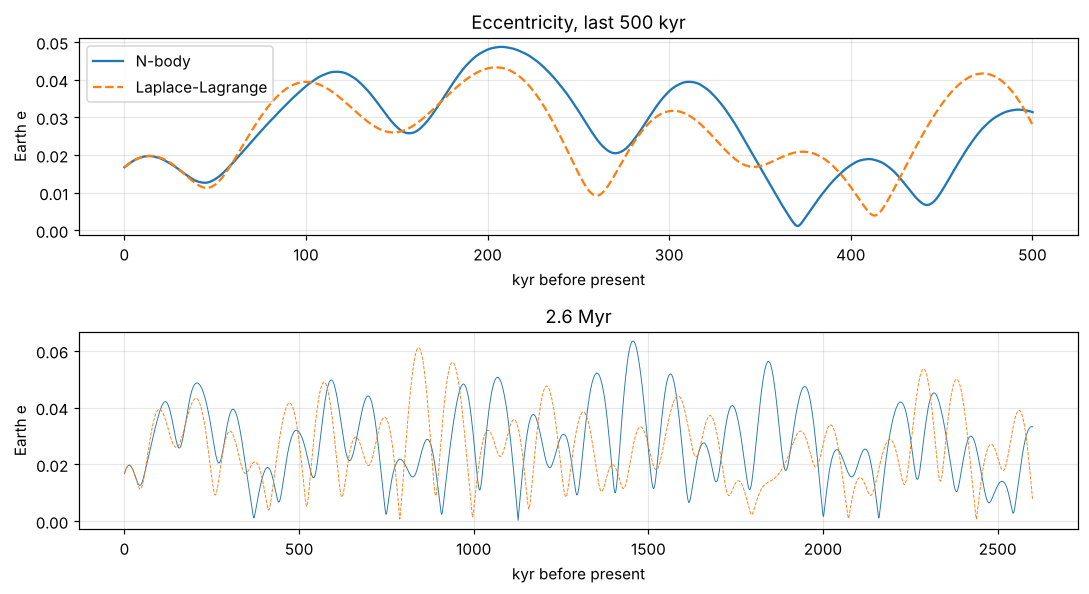

In [11]:
# Earth's eccentricity: N-body versus first-order theory (approximately the same starting orbit, not identical inputs; see above)
tk_nb = -t_nb/1e3; order = np.argsort(tk_nb); tk_nb = tk_nb[order]; e_nb = np.abs(Z_nb[order, 2])      # kyr before present, ascending
e_ll = earth_e(np.arange(8), -1e3*tk_nb)

def corr_at_lag(T, L):
    a, b = e_nb[:T+1], e_ll[:T+1]
    if L > 0: a, b = a[L:], b[:-L]
    elif L < 0: a, b = a[:L], b[-L:]
    return np.corrcoef(a, b)[0, 1]
print("window (kyr)   rms(e_nbody - e_LL)   correlation   best lag (kyr)   correlation at best lag")
for T in (200, 500, 1000, 2600):
    rms = np.sqrt(np.mean((e_nb[:T+1] - e_ll[:T+1])**2)); lags = range(-40, 41); cs = [corr_at_lag(T, L) for L in lags]
    print(f"   0-{T:<5d}        {rms:.4f}              {corr_at_lag(T, 0):6.3f}          {list(lags)[int(np.argmax(cs))]:+3d}            {max(cs):6.3f}")

fig, ax = plt.subplots(2, 1, figsize=(10, 5.5))
ax[0].plot(tk_nb[:501], e_nb[:501], label="N-body"); ax[0].plot(tk_nb[:501], e_ll[:501], "--", label="Laplace-Lagrange")
ax[0].set(xlabel="kyr before present", ylabel="Earth e", title="Eccentricity, last 500 kyr"); ax[0].legend()
ax[1].plot(tk_nb, e_nb, lw=.6, label="N-body"); ax[1].plot(tk_nb, e_ll, "--", lw=.6, label="Laplace-Lagrange"); ax[1].set(xlabel="kyr before present", ylabel="Earth e", title="2.6 Myr")
plt.tight_layout(); plt.show()

In [12]:
print("beat    N-body (kyr)   La2010 (kyr)   first-order LL (kyr)")
for x, y, note in pairs:
    print(f"{x}-{y}    {kyr(fq[x]-fq[y]):8.1f}      {kyr(laskar_2011[x]-laskar_2011[y]):8.1f}       {kyr(g_all[i_of[x]]-g_all[i_of[y]]):8.1f}")

beat    N-body (kyr)   La2010 (kyr)   first-order LL (kyr)
g2-g5       419.1         405.6          358.5
g4-g5        94.0          94.9           90.8
g3-g5        96.4          98.9           95.3
g4-g2       121.2         123.9          121.6
g3-g2       125.2         130.7          129.8


In [13]:
# Step-size check: the first 500 kyr again with a 1.5-day step (cached in nbody_dt1p5_500kyr.npz; about 3 min if recomputed)
if not os.path.exists("nbody_dt1p5_500kyr.npz"):
    run_nbody(T_yr=5e5, dt_days=1.5, out="nbody_dt1p5_500kyr.npz")
fine = np.load("nbody_dt1p5_500kyr.npz")["Z"]; coarse = nb["Z"][:len(fine)]
print("planet    max |dz|     rms |dz|    rms |z|     (3-day step vs 1.5-day step, 0 to 500 kyr)")
for j in (2, 4, 5):
    d = np.abs(coarse[:, j] - fine[:, j])
    print(f"{names[j]:8s}  {d.max():.2e}    {np.sqrt((d**2).mean()):.2e}   {np.sqrt((np.abs(coarse[:, j])**2).mean()):.3f}")

planet    max |dz|     rms |dz|    rms |z|     (3-day step vs 1.5-day step, 0 to 500 kyr)
Earth     3.78e-05    1.36e-05   0.029
Jupiter   8.63e-06    2.85e-06   0.045
Saturn    1.71e-05    4.07e-06   0.060


**What the N-body run shows.** The measured frequencies (table in B.3) give an estimate of the error of the first-order theory. $g_5$ is $12\,\%$ low and $g_6$ is $16\,\%$ low against the N-body values ($g_7$ is $9\,\%$ low and $g_8$ is $6\,\%$ low); the inner modes $g_2,g_3,g_4$ are within about 2 %. The N-body $g_5$ agrees with La2010 to $0.2\,\%$. The N-body $g_6$ is $4.7\,\%$ below La2010, and $g_1$ is $6.4\,\%$ below, so this integration is itself not a replacement for La2010 in those modes (no relativity, plain `plan94` initial conditions). A step-size check over the first 500 kyr is shown above (Earth's $z$ differs by at most $4\times10^{-5}$ between the 3-day and 1.5-day runs, against a typical size of 0.03); no conservation diagnostic is included, and the check does not extend to the full 2.6 Myr.

The 405 kyr term involves $g_5$ (Jupiter), where first-order theory is weakest: it gives 358 kyr against 419 kyr from the N-body ($-14\,\%$) and 406 kyr from La2010. The ~95 to 130 kyr group is within 4 % of the N-body values. The *structure* (a 400 kyr term and a cluster near 100 kyr) is reproduced; the period of the *Jupiter-linked* term is not.

For Earth's $e(t)$ itself, first-order theory follows the N-body curve well at first (correlation 0.94 over the last 200 kyr, rms difference 0.004 against a standard deviation of 0.010) and then drifts out of phase: the correlation is 0.67 over 500 kyr and 0.26 over 1 Myr, and the best-matching lag grows with the window. This is the effect of the wrong $g_5$ and $g_6$ on the phases, and it is the reason the later parts use the series for spectra and not for dating individual events.

## Part C: How many planets do we need?
A "minimal" version using only Earth and Jupiter is tempting. We test it.

Earth + Jupiter                  g = [0.01 7.07]   beat periods of the main modes (kyr): [184]
Earth + Jupiter + Saturn         g = [ 3.5   7.4  22.19]   beat periods of the main modes (kyr): [332]
Venus, Earth, Jupiter, Saturn    g = [ 3.5   7.03 17.29 22.19]   beat periods of the main modes (kyr): [69, 85, 94, 126, 265, 367]
Mercury, Venus, Earth            g = [ 1.05  3.86 11.62]   beat periods of the main modes (kyr): [123, 167, 461]
all 8 planets                    g = [ 0.63  2.71  3.73  5.46  7.35 17.33 18.   22.51]   beat periods of the main modes (kyr): [69, 76, 85, 91, 95, 103, 109, 122, 130, 250, 287, 359, 688, 749, 1926]


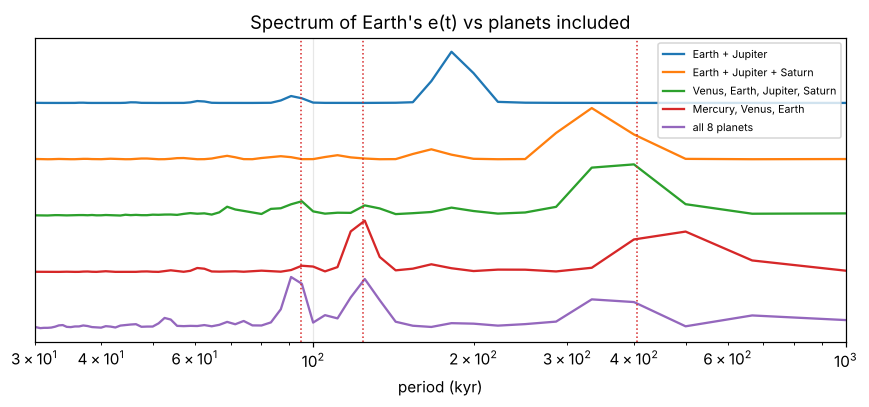

In [14]:
sets = {"Earth + Jupiter": [2,4], "Earth + Jupiter + Saturn": [2,4,5], "Venus, Earth, Jupiter, Saturn": [1,2,4,5],
        "Mercury, Venus, Earth": [0,1,2], "all 8 planets": list(range(8))}
fig, ax = plt.subplots(figsize=(8, 3.8))
for k, (name, idx) in enumerate(sets.items()):
    idx = np.array(idx); e = earth_e(idx, t); s = e - e.mean()
    Fs = np.abs(np.fft.rfft(s*np.hanning(len(s)))); ax.plot(1/fr[1:]/1e3, Fs[1:]/Fs.max() + 1.1*(len(sets)-1-k), label=name)
    g, V, c = secular(idx); w = np.abs(V[list(idx).index(2)]*c); big = np.where(w > 0.1*w.max())[0]     # modes that carry Earth's e
    beats = sorted(round(kyr(abs(g[i]-g[j]))) for x, i in enumerate(big) for j in big[x+1:] if abs(g[i]-g[j]) > 0.05)
    print(f"{name:32s} g = {np.round(g, 2)}   beat periods of the main modes (kyr): {beats}")
for p in (95, 124, 405): ax.axvline(p, color="C3", ls=":", lw=1)
ax.set(xscale="log", xlim=(30, 1000), xlabel="period (kyr)", yticks=[], title="Spectrum of Earth's e(t) vs planets included"); ax.legend(fontsize=7)
plt.tight_layout(); plt.show()

The periods in the printout come from the differences of the mode frequencies, so they do not depend on the resolution of the spectrum. Earth + Jupiter (+ Saturn) gives one beat among the retained dominant modes (184 or 332 kyr) and no ~100 kyr group. Venus, Earth, Jupiter and Saturn give a 367 kyr term together with 94 to 126 kyr terms, which is the structure of the full solution (359 kyr and 91 to 130 kyr at first order). It is the smallest of the sets tested that has both. Mercury, Venus and Earth alone give 123, 167 and 461 kyr, which also looks similar, so matching the observed periods by itself does not show which planets cause them. In the full solution the 405 kyr term is $g_2-g_5$, a Venus-mode against a Jupiter-mode difference [4]. The "Earth and Jupiter only" minimal option does not work.

## Part D: Climatic precession (19 to 23 kyr)
The equinox precesses retrograde along the moving ecliptic at the general precession rate $p_A=50.288''$/yr (Part A.4), while the perihelion advances at rate $g$. Seasons relative to perihelion repeat at the combined rate $p+g$. This is the classic point of confusion: **26 kyr is the spin precession, 19 to 23 kyr is the climatic precession**.

In [15]:
p_obs = 50.288                  # general precession in longitude (IAU 2006), arcsec/yr
print("perihelion rate g (arcsec/yr)   climatic precession period (kyr)")
for lab in ("g5", "g2", "g1", "g3", "g4"):
    gg = laskar_2011[lab]; print(f"   {lab}  {gg:7.3f}                      {kyr(p_obs+gg):6.1f}")
print("spin precession alone:", round(kyr(p_obs), 1), "kyr")

perihelion rate g (arcsec/yr)   climatic precession period (kyr)
   g5    4.258                        23.8
   g2    7.453                        22.4
   g1    5.590                        23.2
   g3   17.368                        19.2
   g4   17.916                        19.0
spin precession alone: 25.8 kyr


These are 23.8, 23.2, 22.4, 19.2 and 19.0 kyr, matching the principal astronomical periods of the climatic-precession band, about 23, 22, 19 and 19 kyr [6, 7].

## Part E: Obliquity, insolation and the ice record

### E.1 Obliquity (41 kyr)
Part A treated the orbital plane as fixed. It is not: the other planets make the orbit normal $\hat{\mathbf n}$ precess slowly. The spin axis keeps precessing about the *instantaneous* $\hat{\mathbf n}$, so the angle between them, the obliquity $\varepsilon$, changes.

**Spin axis.** The averaged torque of Part A in vector form is

$$\dot{\hat{\mathbf s}}=-\alpha\,(\hat{\mathbf n}\cdot\hat{\mathbf s})\,(\hat{\mathbf n}\times\hat{\mathbf s}),\qquad \alpha\simeq\frac{50.385''/\text{yr}}{\cos\varepsilon_0}=54.9''/\text{yr},$$

with $\alpha$ set so that the rate for a fixed normal is the IAU 2006 equatorial precession of Part A.4 (changes of the Earth's ellipticity and of the Moon's distance over Myr are ignored). Taking $\hat{\mathbf n}=\hat{\mathbf z}$ and $\hat{\mathbf s}=(\sin\varepsilon,0,\cos\varepsilon)$ gives back $\dot\psi=-\alpha\cos\varepsilon$.

**Orbit normal.** The inclination analogue of Part B uses $p_j=\sin I_j\sin\Omega_j$, $q_j=\sin I_j\cos\Omega_j$ and $\zeta_j=q_j+ip_j$:

$$\dot{\boldsymbol\zeta}=+i\,\mathsf B\,\boldsymbol\zeta,\qquad B_{jj}=-\frac{n_j}{4}\sum_{k\ne j}\frac{m_k}{M_\odot+m_j}\alpha_{jk}\bar\alpha_{jk}b^{(1)}_{3/2},\quad B_{jk}=+\frac{n_j}{4}\frac{m_k}{M_\odot+m_j}\alpha_{jk}\bar\alpha_{jk}b^{(1)}_{3/2}.$$

The eigenvalues $s_i$ are negative (nodes regress), and one is zero (the invariable plane). The orbit normal is $\hat{\mathbf n}=(p,-q,\sqrt{1-p^2-q^2})$ in the J2000 ecliptic frame, where Earth has $I_\oplus=0$ at $t=0$.

**Expected periods.** Linearising, $\varepsilon$ oscillates at $p+s_i$. For $s_3=-18.7''$/yr this gives $1296\,\text{kyr}/(50.4-18.7)\approx41$ kyr.

**Initial spin axis.** The north celestial pole lies at ecliptic longitude $90^\circ$, so $\hat{\mathbf s}_0=(0,\sin\varepsilon_0,\cos\varepsilon_0)$ with $\varepsilon_0=23.439^\circ$.

obliquity today 23.439 deg;  d(eps)/dt today = -0.474 arcsec/yr   (observed about -0.47)
range over last 1 Myr: 22.08 to 24.44 deg
p + s_i periods (kyr): [53.1 41.  39.6 29.6]
spectral peaks of eps(t) (kyr): [40.6, 53.1]


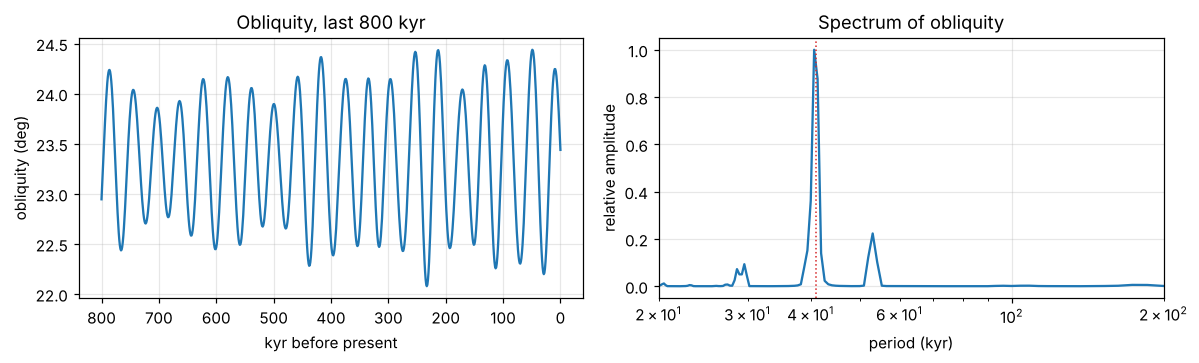

In [16]:
I0  = np.radians([7.005, 3.395, 0.0, 1.850, 1.303, 2.489, 0.773, 1.770])      # J2000 inclinations to the J2000 ecliptic
Om0 = np.radians([48.33, 76.68, 0.0, 49.56, 100.46, 113.67, 74.02, 131.78])   # J2000 nodes

def incl_matrix():
    n = ASEC_REV/a**1.5; N = len(a); B = np.zeros((N, N))
    for j in range(N):
        for k in range(N):
            if j == k: continue
            al, alb = (a[j]/a[k],)*2 if a[j] < a[k] else (a[k]/a[j], 1.0)
            c = 0.25*n[j]*m[k]/(1+m[j])*al*alb*laplace_b(1.5, 1, al)
            B[j, j] -= c; B[j, k] = c
    return B

B = incl_matrix()
s_modes, Vs = np.linalg.eig(B); s_modes, Vs = s_modes.real, Vs.real
cs = np.linalg.solve(Vs, np.sin(I0)*np.cos(Om0) + 1j*np.sin(I0)*np.sin(Om0))
rad = lambda x: np.radians(x/3600.0)                                        # arcsec/yr -> rad/yr

g_vals, V_g, c_g = secular(np.arange(8))                                    # eccentricity solution (Part B)
def z_earth(t):                                                             # e*exp(i*varpi) of Earth, t in yr (negative = past)
    return sum(V_g[2, i]*c_g[i]*np.exp(1j*rad(g_vals[i])*t) for i in range(8))
def normal(t):                                                              # orbit normal of Earth
    zt = sum(Vs[2, i]*cs[i]*np.exp(1j*rad(s_modes[i])*t) for i in range(8)); q, p = zt.real, zt.imag
    return np.array([p, -q, np.sqrt(1 - p*p - q*q)])

alpha = rad(50.385/np.cos(np.radians(23.439)))
def spin_rhs(t, s):
    nh = normal(t); return -alpha*(nh @ s)*np.cross(nh, s)
eps_0 = np.radians(23.439); s_init = np.array([0, np.sin(eps_0), np.cos(eps_0)])
T_BACK = -2.6e6
spin = solve_ivp(spin_rhs, (0, T_BACK), s_init, method="DOP853", rtol=1e-10, atol=1e-12, dense_output=True)
eps_of = lambda t: np.degrees(np.arccos(np.clip(spin.sol(t) @ normal(t), -1, 1)))

# checks
fwd = solve_ivp(spin_rhs, (0, 100.0), s_init, method="DOP853", rtol=1e-12, atol=1e-14, dense_output=True)
deps = (np.degrees(np.arccos(fwd.sol(100.0) @ normal(100.0))) - eps_of(0.0))*3600/100.0
tk_grid = np.arange(0, 2600.1, 1.0)                                         # kyr before present
eps_series = np.array([eps_of(-1e3*x) for x in tk_grid])
print(f"obliquity today {eps_of(0.0):.3f} deg;  d(eps)/dt today = {deps:.3f} arcsec/yr   (observed about -0.47)")
print(f"range over last 1 Myr: {eps_series[:1001].min():.2f} to {eps_series[:1001].max():.2f} deg")
print("p + s_i periods (kyr):", np.round(ASEC_REV/(50.385 + np.sort(s_modes))/1e3, 1)[:4])

sig = eps_series - eps_series.mean(); F = np.abs(np.fft.rfft(sig*np.hanning(len(sig)))); fr = np.fft.rfftfreq(len(sig), 1.0)
pk = sorted([i for i in range(2, len(F)-1) if F[i] > F[i-1] and F[i] > F[i+1] and F[i] > .1*F.max()], key=lambda i: -F[i])[:3]
print("spectral peaks of eps(t) (kyr):", [round(float(1/fr[i]), 1) for i in pk])

fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
ax[0].plot(tk_grid[:801], eps_series[:801]); ax[0].invert_xaxis(); ax[0].set(xlabel="kyr before present", ylabel="obliquity (deg)", title="Obliquity, last 800 kyr")
ax[1].plot(1/fr[1:], F[1:]/F.max()); ax[1].set(xscale="log", xlim=(20, 200), xlabel="period (kyr)", ylabel="relative amplitude", title="Spectrum of obliquity")
ax[1].axvline(41, color="C3", ls=":", lw=1)
plt.tight_layout(); plt.show()

**Result.** The spin equation with a moving orbit normal gives $d\varepsilon/dt=-0.47''$/yr today, matching the observed rate, and an obliquity range of 22.1° to 24.4° over the last Myr. The spectrum has its main peak near 41 kyr (40.6 kyr on the 2.6 Myr grid; from $s_3$, with $s_4$ at 39.6 kyr as a close neighbour) and a second one near 53 kyr (from $s_6$).

### E.2 Daily insolation at 65°N
Milankovitch's argument is that summer insolation at high northern latitudes controls ice-sheet growth [8, 9]. For the daily-mean insolation at latitude $\varphi$ and true solar longitude $\lambda$ [6],

$$Q=\frac{S_0}{\pi}\frac{1}{\rho^2}\Big(h_0\sin\varphi\sin\delta+\cos\varphi\cos\delta\sin h_0\Big),\quad \sin\delta=\sin\varepsilon\sin\lambda,\quad \cos h_0=-\tan\varphi\tan\delta,$$

with $\rho=r/a=(1-e^2)/(1+e\cos\nu)$ and $\nu=\lambda-\varpi$. Here $\varpi$ is the longitude of perihelion of the Sun's apparent orbit measured from the **moving** vernal equinox, which is Earth's heliocentric $\varpi_\oplus$ (from Part B, measured from the fixed J2000 equinox) converted to the moving equinox, plus $180^\circ$. The perihelion direction follows from the orbit's node $\Omega$, inclination $I$ and argument of perihelion $\omega=\varpi-\Omega$, and the vernal equinox direction is $\hat{\boldsymbol\gamma}\propto\hat{\mathbf s}\times\hat{\mathbf n}$. All three orbital parameters $(\varepsilon,e,\varpi)$ come from the code above. We take the summer solstice, $\lambda=90^\circ$, and $S_0=1361$ W/m².

Check at $t=0$: $\varpi=282.9^\circ$, so at the June solstice Earth is near aphelion ($\rho>1$).

The first-order frequency errors measured in B.3 shift the phase of the eccentricity and precession terms: first-order $e(t)$ follows the N-body $e(t)$ closely for the last ~200 kyr and loses correlation beyond ~1 Myr. The series below are therefore used for their spectra and not for dating individual events. Times are before J2000; the LR04 scale is before 1950, a difference of 50 yr that is far below the 1 kyr grid.

t=0: Q = 477.9 W/m2, eps = 23.44 deg, e = 0.0167, varpi = 282.9 deg


Q(65N, solstice) range over 2.6 Myr: 432 to 560 W/m2


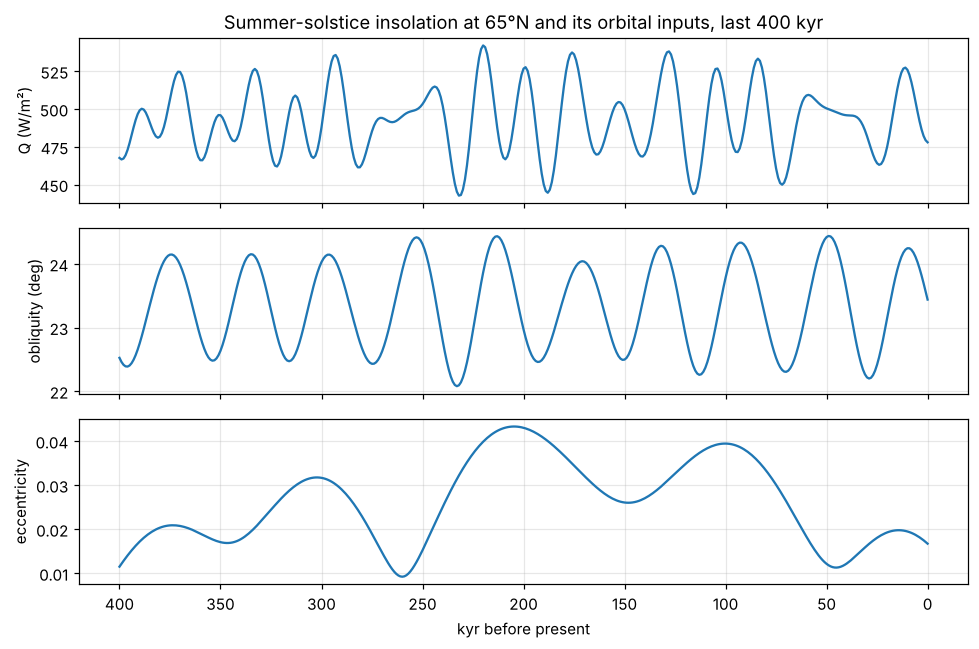

In [17]:
def insolation(t, lat=65.0, lam=np.pi/2, S0=1361.0):
    '''Daily-mean insolation (W/m2) at latitude lat (deg), solar longitude lam, time t (yr, negative = past). Returns Q, eps, e, varpi.'''
    phi = np.radians(lat); nh = normal(t); sv = spin.sol(t) if t != 0 else s_init
    sv = sv/np.linalg.norm(sv); ec = np.arccos(np.clip(nh @ sv, -1, 1))
    gam = np.cross(sv, nh); gam /= np.linalg.norm(gam)                      # vernal equinox direction
    perp = np.cross(nh, gam)
    z = z_earth(t); e = abs(z); vp = np.angle(z)                            # vp = Omega + omega, longitude of perihelion
    zt = sum(Vs[2, i]*cs[i]*np.exp(1j*rad(s_modes[i])*t) for i in range(8)); sI = abs(zt); cI = np.sqrt(1 - sI*sI); Om = np.angle(zt)
    w_ = vp - Om                                                            # argument of perihelion
    P = np.array([np.cos(Om)*np.cos(w_) - np.sin(Om)*cI*np.sin(w_), np.sin(Om)*np.cos(w_) + np.cos(Om)*cI*np.sin(w_), sI*np.sin(w_)])
    varpi = (np.arctan2(P @ perp, P @ gam) + np.pi) % (2*np.pi)             # Berger convention
    nu = lam - varpi; rho = (1 - e*e)/(1 + e*np.cos(nu))
    dec = np.arcsin(np.sin(ec)*np.sin(lam))
    h0 = np.arccos(np.clip(-np.tan(phi)*np.tan(dec), -1, 1))
    Q = S0/np.pi/rho**2*(h0*np.sin(phi)*np.sin(dec) + np.cos(phi)*np.cos(dec)*np.sin(h0))
    return Q, np.degrees(ec), e, np.degrees(varpi)

Q0, e_0, ee0, vp0 = insolation(0.0)
print(f"t=0: Q = {Q0:.1f} W/m2, eps = {e_0:.2f} deg, e = {ee0:.4f}, varpi = {vp0:.1f} deg")

res = np.array([insolation(-1e3*x) for x in tk_grid])                      # columns: Q, eps, e, varpi
Qs, eps_s, e_s, varpi_s = res.T
print(f"Q(65N, solstice) range over 2.6 Myr: {Qs.min():.0f} to {Qs.max():.0f} W/m2")

fig, ax = plt.subplots(3, 1, figsize=(9, 6), sharex=True)
sl = slice(0, 401)
ax[0].plot(tk_grid[sl], Qs[sl]);    ax[0].set_ylabel("Q (W/m²)")
ax[1].plot(tk_grid[sl], eps_s[sl]); ax[1].set_ylabel("obliquity (deg)")
ax[2].plot(tk_grid[sl], e_s[sl]);   ax[2].set_ylabel("eccentricity"); ax[2].set_xlabel("kyr before present"); ax[2].invert_xaxis()
ax[0].set_title("Summer-solstice insolation at 65°N and its orbital inputs, last 400 kyr")
plt.tight_layout(); plt.show()

### E.3 Comparison with the LR04 benthic δ¹⁸O stack
LR04 [10] is the average of 57 benthic δ¹⁸O records and measures global ice volume plus deep-ocean temperature (higher δ¹⁸O means more ice). Its age model was tuned to a simple ice model forced by 21 June insolation at 65°N [10], so the agreement at 23 and 41 kyr is partly built in, and a match in those bands says less than it appears to. The age model was not directly tuned to an imposed 100 kyr sinusoid, but its target is a nonlinear ice model driven by insolation, so the 100 kyr band is not a fully independent test.

We compare the spectra of $Q$ and of LR04 in two windows: 0 to 1 Myr (the 100 kyr world) and 1.5 to 2.5 Myr (the 41 kyr world). Band fractions are the share of the total power in a Hann-windowed periodogram of the linearly detrended series.

LR04 points: 2115  time span (kyr): 0.0 - 5320.0


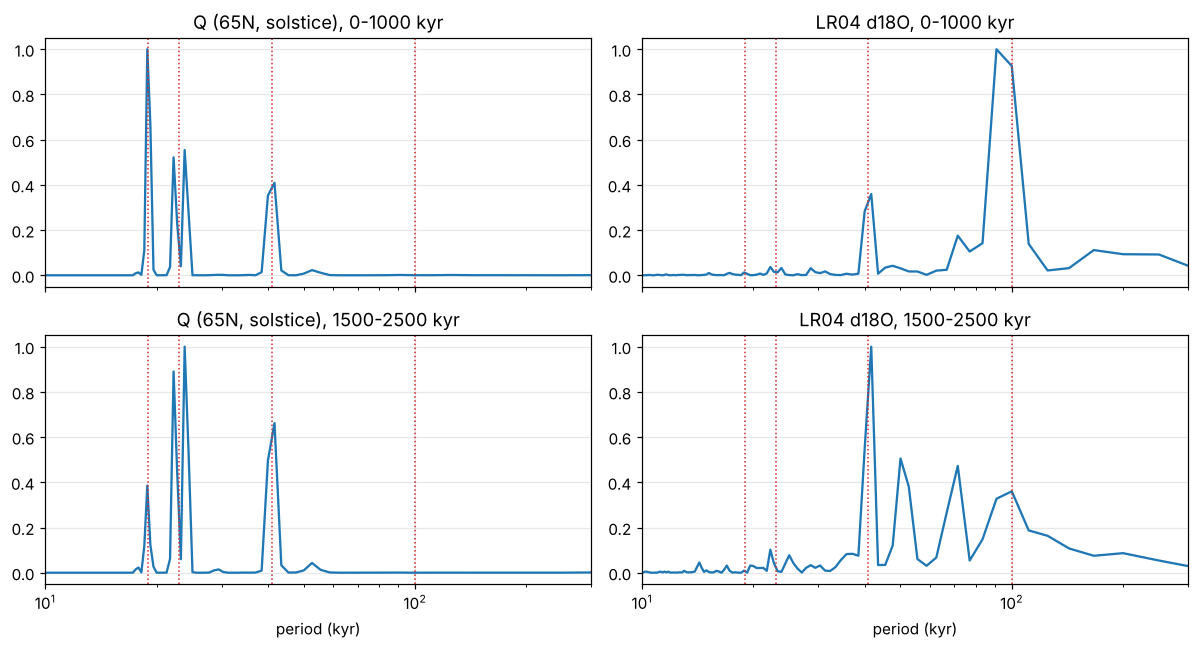

share of periodogram power in band      precession 15-30   obliquity 35-48   80-130 kyr
  0-1000 kyr     Q                          0.80              0.18           0.001
  0-1000 kyr     LR04                       0.06              0.18           0.534
  1500-2500 kyr  Q                          0.74              0.24           0.000
  1500-2500 kyr  LR04                       0.10              0.31           0.183


In [18]:
import os, urllib.request
from scipy.signal import periodogram

def load_lr04(path="LR04stack.txt"):
    if not os.path.exists(path):
        url = "https://raw.githubusercontent.com/benmarwick/gsloid/master/data-raw/lisiecki2005.txt"    # NOAA NCEI file, first table
        try:
            raw = urllib.request.urlopen(url, timeout=60).read().decode("latin-1")
        except Exception as err:
            raise RuntimeError("Could not download LR04. Place LR04stack.txt (columns: age in kyr, d18O, std error) next to this notebook.") from err
        rows = []
        for line in raw.splitlines():
            p = line.split()
            try: v = [float(x) for x in p] if len(p) == 3 else None
            except ValueError: v = None
            if v is not None:
                if rows and v[0] <= rows[-1][0]: break
                rows.append(v)
            elif rows: break
        np.savetxt(path, np.array(rows), fmt="%g", header="Time_kyr d18O_permil StdErr (LR04, Lisiecki & Raymo 2005)")
    return np.loadtxt(path)

lr = load_lr04(); d18 = np.interp(tk_grid, lr[:, 0], lr[:, 1])
print("LR04 points:", len(lr), " time span (kyr):", lr[0, 0], "-", lr[-1, 0])

def spec(x):
    f, P = periodogram(x - x.mean(), fs=1.0, window="hann", detrend="linear")        # fs in cycles/kyr
    return 1/f[1:], P[1:]
def band(x, lo, hi):
    per, P = spec(x); return P[(per >= lo) & (per <= hi)].sum()/P.sum()

windows = {"0-1000 kyr": (0, 1000), "1500-2500 kyr": (1500, 2500)}
fig, ax = plt.subplots(2, 2, figsize=(11, 6), sharex=True)
for r_i, (name, (a0, a1)) in enumerate(windows.items()):
    for c_i, (lab, x) in enumerate((("Q (65N, solstice)", Qs), ("LR04 d18O", d18))):
        per, P = spec(x[a0:a1+1]); ax[r_i, c_i].plot(per, P/P.max())
        ax[r_i, c_i].set(xscale="log", xlim=(10, 300), title=f"{lab}, {name}")
        for p in (19, 23, 41, 100): ax[r_i, c_i].axvline(p, color="C3", ls=":", lw=1)
for a_ in ax[1]: a_.set_xlabel("period (kyr)")
plt.tight_layout(); plt.show()

print("share of periodogram power in band      precession 15-30   obliquity 35-48   80-130 kyr")
for name, (a0, a1) in windows.items():
    for lab, x in (("Q   ", Qs), ("LR04", d18)):
        xx = x[a0:a1+1]; print(f"  {name:14s} {lab}                     {band(xx,15,30):6.2f}            {band(xx,35,48):6.2f}          {band(xx,80,130):6.3f}")

**Result.** The insolation spectrum is dominated by precession (15 to 30 kyr) plus obliquity, with very little power at 80 to 130 kyr (table above), even though the eccentricity itself has strong ~100 kyr terms (Part B). The eccentricity cycles mainly modulate the *amplitude* of the precession term (the factor $e$ in $e\sin\varpi$); direct power in the 100 kyr band is very weak. LR04 in the last Myr is the opposite: about half its power (0.53) sits at 80 to 130 kyr and only ~6 % in the precession band. Before ~1 Myr, LR04 has more obliquity power and the 100 kyr band shrinks. A response that is simply proportional to $Q$ would carry the spectrum of $Q$, and the record does not.

### E.4 The 100 kyr problem
The annual-mean insolation at the top of the atmosphere, at any latitude, depends on $e$ only through $1/\sqrt{1-e^2}$ (at fixed obliquity), a change of ~0.2 % for $e=0.06$, and the 65°N solstice $Q$ has very little 100 kyr power (above). Yet the late-Pleistocene ice volume has its strongest power there, and the dominant period was 41 kyr before the mid-Pleistocene transition at about 1 Myr, with no change in orbital forcing. The table lists a selection of proposals from the literature, not a complete survey. They disagree, and none is settled:

| Position | Argument | Source |
|---|---|---|
| Obliquity pacing | Terminations occur at times of high obliquity, every second or third 41 kyr cycle; the 100 kyr scale is the average spacing. A statistical test rejects independence of terminations from obliquity at the 5 % level but not from eccentricity or precession; failing to reject precession does not show that it plays no role, and a later analysis found evidence for combined obliquity and precession pacing (Huybers 2011 [15]). | Huybers & Wunsch 2005 [11], https://dash.harvard.edu/entities/publication/73120378-873e-6bd4-e053-0100007fdf3b |
| Orbital inclination | Proposed: the 100 kyr cycle comes from the inclination of Earth's orbital plane relative to the invariable plane, which has a 100 kyr period, and not from eccentricity. The proposed climate link is accretion of dust or meteoroids, which is not an insolation effect. | Muller & MacDonald 1995, 1997 [12], https://muller.lbl.gov/papers/sciencespectra.htm |
| Internal nonlinear dynamics | Multiple equilibria of the climate system produce the timing of the glacial cycles within the framework of astronomical forcing. | Paillard 1998 [13], https://doi.org/10.1038/34891 |
| Overview of open issues | Short overview, noting that as of 2008 a complete theory of the ice ages was still elusive. | Raymo & Huybers 2008 [14], https://phuybers.sites.fas.harvard.edu/Doc/Raymo_Nature2008.pdf |

### E.5 Toy threshold model (illustration only)
Ice volume $v\in[0,1]$ grows at a constant rate. A termination starts when $v$ exceeds a minimum size $v_\text{min}$ and the normalised insolation $Q_n$ exceeds a threshold that falls as the ice sheet grows, $\theta_0-\theta_1 v$. Then $v$ collapses at a fast constant rate. The model is not fitted to LR04 and is not a reproduction of Paillard's model [13]. Its spacing is largely set by the assumed fill time, so it shows how a threshold converts a 20 to 40 kyr forcing into a longer cycle, not that this is the cause.

0-1000 kyr     terminations:  9  spacing mean 104 kyr  (min 100, max 118)
1500-2500 kyr  terminations:  9  spacing mean 104 kyr  (min 100, max 109)


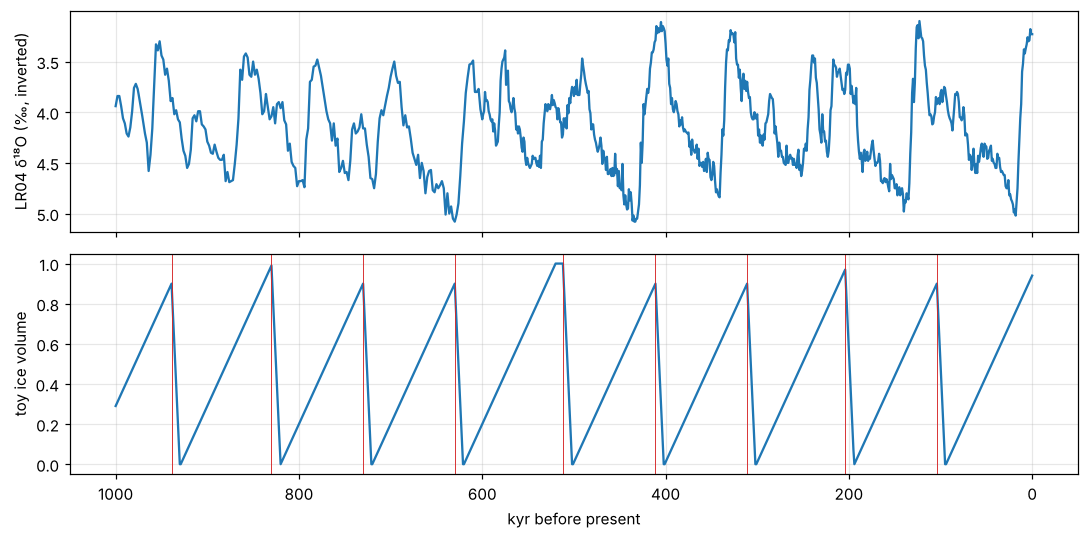

In [19]:
Qn = (Qs - Qs.mean())/Qs.std()
def toy(Qn, tk, r=1/100., rd=1/10., th0=1.0, th1=1.0, vmin=0.9):
    assert np.allclose(np.diff(tk), 1.0)                                    # rates r, rd are per 1 kyr sample
    t = tk[::-1]; q = Qn[::-1]                                              # forward in time (kyr before present decreasing)
    v, state, out, term = 0.0, "grow", [], []
    for ti, qi in zip(t, q):
        if state == "grow":
            v = min(v + r, 1.0)
            if v >= vmin and qi > th0 - th1*v: state = "collapse"; term.append(ti)
        else:
            v -= rd
            if v <= 0: v, state = 0.0, "grow"
        out.append(v)
    return np.array(out)[::-1], np.array(term)

v_toy, term = toy(Qn, tk_grid)
for name, (a0, a1) in windows.items():
    tt = term[(term >= a0) & (term < a1)]
    print(f"{name:14s} terminations: {len(tt):2d}  spacing mean {(-np.diff(tt)).mean():.0f} kyr  (min {(-np.diff(tt)).min():.0f}, max {(-np.diff(tt)).max():.0f})")

fig, ax = plt.subplots(2, 1, figsize=(10, 5), sharex=True)
ax[0].plot(tk_grid[:1001], d18[:1001]); ax[0].invert_yaxis(); ax[0].set_ylabel("LR04 δ¹⁸O (‰, inverted)")
ax[1].plot(tk_grid[:1001], v_toy[:1001]); ax[1].set_ylabel("toy ice volume"); ax[1].set_xlabel("kyr before present"); ax[1].invert_xaxis()
for x in term[term < 1000]: ax[1].axvline(x, color="C3", lw=.6)
plt.tight_layout(); plt.show()

**Result.** With the minimum-size condition the toy model gives a sawtooth with a mean spacing near 100 kyr in the last Myr, and terminations occur only when the normalised insolation exceeds the falling threshold, by construction. The same parameters give a similar ~100 kyr spacing in the 1.5 to 2.5 Myr window, where the record shows 41 kyr cycles, so the model does not reproduce the mid-Pleistocene transition. The model has no mechanism for the transition. A slowly changing parameter (for example $v_\text{min}$) could be added, but that would put the transition into the parameter and leave it unexplained.

## References
1. Murray, C. D. & Dermott, S. F. (1999). *Solar System Dynamics*. Cambridge University Press, ch. 7 (secular perturbations, Laplace coefficients).
2. Fitzpatrick, R. *Celestial Mechanics* lecture notes, "Secular evolution of planetary orbits", Table 10.1 (source of the first-order frequencies compared in Part B). https://farside.ph.utexas.edu/teaching/celestial/Celestial/node91.html (accessed 4 November 2026)
3. Brouwer, D. & van Woerkom, A. J. J. (1950). The secular variations of the orbital elements of the principal planets. *Astronomical Papers Prepared for the Use of the American Ephemeris and Nautical Almanac* 13, part 2, 81-107 (original source of first-order secular theory for the planets; the numbers compared here are taken from [2]).
4. Laskar, J. et al. (2011). La2010: a new orbital solution for the long-term motion of the Earth. *Astronomy & Astrophysics* 532, A89 (Table 6, secular frequencies). https://www.aanda.org/articles/aa/full_html/2011/08/aa16836-11/T6.html
5. Alnajjarine, A., Mogavero, F. & Laskar, J. (2025). Numerical approach to second-order canonical perturbation theory in the planetary 3-body problem: Application to exoplanets. *Physical Review D* 112, 023038, doi:10.1103/8kn1-ksg3; arXiv:2506.13745 (errors of first-order theory in $g_5$, $g_6$).
6. Berger, A. L. (1978). Long-term variations of daily insolation and Quaternary climatic changes. *Journal of the Atmospheric Sciences* 35, 2362-2367.
7. Laskar, J. et al. (2004). A long-term numerical solution for the insolation quantities of the Earth. *Astronomy & Astrophysics* 428, 261-285, doi:10.1051/0004-6361:20041335.
8. Milankovitch, M. (1941). *Kanon der Erdbestrahlung und seine Anwendung auf das Eiszeitenproblem*. Royal Serbian Academy, Belgrade.
9. Hays, J. D., Imbrie, J. & Shackleton, N. J. (1976). Variations in the Earth's orbit: pacemaker of the ice ages. *Science* 194, 1121-1132, doi:10.1126/science.194.4270.1121.
10. Lisiecki, L. E. & Raymo, M. E. (2005). A Pliocene-Pleistocene stack of 57 globally distributed benthic δ¹⁸O records. *Paleoceanography* 20, PA1003, doi:10.1029/2004PA001071. Data: NOAA NCEI, https://doi.org/10.25921/K88J-0106
11. Huybers, P. & Wunsch, C. (2005). Obliquity pacing of the late Pleistocene glacial terminations. *Nature* 434, 491-494, doi:10.1038/nature03401.
12. Muller, R. A. & MacDonald, G. J. (1995). Glacial cycles and orbital inclination. *Nature* 377, 107-108; (1997). Glacial cycles and astronomical forcing. *Science* 277, 215-218, doi:10.1126/science.277.5323.215.
13. Paillard, D. (1998). The timing of Pleistocene glaciations from a simple multiple-state climate model. *Nature* 391, 378-381, doi:10.1038/34891.
14. Raymo, M. E. & Huybers, P. (2008). Unlocking the mysteries of the ice ages. *Nature* 451, 284-285, doi:10.1038/nature06589 (short feature article).
15. Huybers, P. (2011). Combined obliquity and precession pacing of late Pleistocene deglaciations. *Nature* 480, 229-232, doi:10.1038/nature10626.
16. Rein, H. & Liu, S.-F. (2012). REBOUND: an open-source multi-purpose N-body code for collisional dynamics. *Astronomy & Astrophysics* 537, A128, doi:10.1051/0004-6361/201118085.
17. Rein, H. & Tamayo, D. (2015). WHFast: a fast and unbiased implementation of a symplectic Wisdom-Holman integrator for long-term gravitational simulations. *Monthly Notices of the Royal Astronomical Society* 452, 376-388, doi:10.1093/mnras/stv1257.
18. Simon, J. L., Bretagnon, P., Chapront, J., Chapront-Touze, M., Francou, G. & Laskar, J. (1994). Numerical expressions for precession formulae and mean elements for the Moon and the planets. *Astronomy & Astrophysics* 282, 663-683 (basis of the ERFA/SOFA `plan94` planetary theory used in B.3). ERFA/pyerfa: https://github.com/liberfa/erfa
19. Hilton, J. L. et al. (2006). Report of the IAU Division I Working Group on Precession and the Ecliptic. *Celestial Mechanics and Dynamical Astronomy* 94, 351-367 (IAU 2006 precession constants used in A.4).